# Task 3a: Automated ROI selection for ALINA

| # | Method | Family | What it does |
|---|---|---|---|
| M1 | `prior` | Statistical baseline | Median of the manual ROIs from the *other* videos (leave-one-video-out). Without manual labels it falls back to a hand-set default. |
| M2 | `hough` | Classical CV | HSV yellow mask → centerline component selection → Canny + probabilistic Hough → trapezoid fit |
| M3 | `vlm_zeroshot` / `vlm_fewshot` | Multimodal LLM | Claude (`claude-opus-5-5`) gets the frame with a coordinate grid and returns the trapezoid as structured JSON. The few-shot variant adds labeled frames from other videos. |
| M4 | `gdino` | Open-vocabulary detection | Grounding DINO, prompted with *"yellow painted line on the taxiway"* → box → perspective trapezoid |
| M5 | `grounded_sam` | Promptable segmentation | Grounding DINO boxes → SAM masks → trapezoid fit on the mask |
| M6 | `m2f_lanes` | Pretrained road-marking segmenter | Mask2Former trained on Mapillary Vistas; its *Lane Marking* classes → trapezoid fit (tests road → airport domain transfer) |
| M7 | `regressor` | Supervised learning | ImageNet ResNet-18 fine-tuned to regress the 6 ROI parameters from your manual labels (leave-one-video-out, 3 seeds) |

Use a Python 3.10 virtual environment. 
```bash
py -3.10 -m venv venv
venv\Scripts\activate
pip install -e .
pip install torch torchvision
pip install "transformers>=4.45" pillow pandas anthropic ipykernel
python -m ipykernel install --user --name alina
```

Then open this notebook with the `alina` kernel. Methods whose dependencies are missing get skipped with a message instead of failing.

M3 needs Anthropic credentials: `ANTHROPIC_API_KEY`, or an `ant auth login` profile. It costs roughly a few cents per frame. Set `RUN_VLM = False` to skip it.

In [1]:
import os, sys, json, time, random, hashlib, base64, importlib.util, warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "alina").is_dir(), "Start Jupyter from the ALINA repo root."
sys.path.insert(0, str(ROOT))

from alina.config import PipelineConfig
from alina.pipeline import process_image
from alina.roi import select_roi, roi_points_to_quad
from eval.metrics import calculate_precision, calculate_recall, calculate_f1

# ---------------- experiment configuration ----------------
SEED = 42
REGRESSOR_SEEDS = [0, 1, 2]       # M7 is trained once per seed to report variance
WORK_W, WORK_H = 1920, 1080       # resolution of the GT / Labeled_Data coordinates
PIXEL_TOL = 10                    # px tolerance for the pixel-level metric (at 1080p)
RUN_VLM = True                    # M3 calls the Claude API (cached after the first run)
VLM_MODEL = "claude-opus-5-5"
SAVE_ANNOTATED = False            # write ALINA-annotated frames for every method (slow, large)

VIDEOS = ["vidd_1", "vidd_2", "vidd_3"]
RAW = ROOT / "data" / "Raw_Data"
GT_ROOT = ROOT / "data" / "gt_alina_labels"
OUT = ROOT / "outputs" / "task3a"
OUT.mkdir(parents=True, exist_ok=True)
MANUAL_ROI_PATH = OUT / "manual_rois.json"
VLM_CACHE = OUT / "vlm_cache"
VLM_CACHE.mkdir(exist_ok=True)


def has(module):
    return importlib.util.find_spec(module) is not None


HAS_TORCH, HAS_TF, HAS_ANTHROPIC = has("torch"), has("transformers"), has("anthropic")
DEVICE = "cpu"
if HAS_TORCH:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if HAS_TORCH:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed()
print(f"torch={HAS_TORCH} transformers={HAS_TF} anthropic={HAS_ANTHROPIC} device={DEVICE}")

torch=True transformers=True anthropic=True device=cpu


## 1. Data

Each video folder actually contains several non-contiguous clips. For example, vidd_1 is frames 1–20, 1060–1068 and 9000–9020. A first-frame ROI therefore has to carry over a scene cut, which matters for Task 3b.

In [2]:
def frame_id(p):
    return int(p.stem)


def split_clips(paths):
    clips = [[paths[0]]]
    for a, b in zip(paths, paths[1:]):
        if frame_id(b) - frame_id(a) == 1:
            clips[-1].append(b)
        else:
            clips.append([b])
    return clips


FRAMES = {v: sorted((RAW / v).glob("*.jpg")) for v in VIDEOS}
CLIPS = {v: split_clips(FRAMES[v]) for v in VIDEOS}
GT_DIRS = {v: GT_ROOT / "canny_textfiles" / f"canny_textfiles_{i}" for i, v in enumerate(VIDEOS, 1)}
ALINA_REF_DIRS = {v: GT_ROOT / "ALINA_textfiles" / f"ALINA_textfiles_{i}" for i, v in enumerate(VIDEOS, 1)}
GT_FRAMES = {v: [p for p in FRAMES[v] if (GT_DIRS[v] / f"{p.stem}.txt").exists()] for v in VIDEOS}


@lru_cache(maxsize=48)
def load(path):
    # raw frames are 4K; GT coordinates are 1080p
    img = cv2.imread(str(path))
    if img.shape[1] != WORK_W or img.shape[0] != WORK_H:
        img = cv2.resize(img, (WORK_W, WORK_H), interpolation=cv2.INTER_AREA)
    return img


def load_coords(path):
    if not path.exists() or path.stat().st_size == 0:
        return np.empty((0, 2), dtype=np.int32)
    return np.loadtxt(path, dtype=np.int32, ndmin=2).reshape(-1, 2)


pd.DataFrame([
    {
        "video": v,
        "frames": len(FRAMES[v]),
        "clips": " | ".join(f"{c[0].stem}-{c[-1].stem}" for c in CLIPS[v]),
        "frames with GT": len(GT_FRAMES[v]),
    }
    for v in VIDEOS
])

,video,frames,clips,frames with GT
0,vidd_1,50,00001-00020 | 01060-01068 | 09000-09020,7
1,vidd_2,50,00001-00020 | 03650-03670 | 05604-05612,10
2,vidd_3,50,18970-18990 | 40940-40953 | 42370-42384,0


## 2. ROI geometry

In [3]:
PARAM_NAMES = ["y_top", "y_bottom", "x_bl", "x_tl", "x_tr", "x_br"]


def make_quad(y_top, y_bot, x_bl, x_tl, x_tr, x_br):
    return np.array([[x_bl, y_bot], [x_tl, y_top], [x_tr, y_top], [x_br, y_bot]], dtype=float)


def sanitize(quad, shape=(WORK_H, WORK_W), min_h_frac=0.03, min_w_px=24):
    # enforce ALINA's trapezoid convention and keep it inside the frame
    H, W = shape[:2]
    q = np.asarray(quad, dtype=float)
    y_top, y_bot = sorted([q[1, 1], q[0, 1]])
    y_bot = float(np.clip(y_bot, min_h_frac * H, H - 1))
    y_top = float(np.clip(min(y_top, y_bot - min_h_frac * H), 0, H - 1))
    x_bl, x_br = sorted([q[0, 0], q[3, 0]])
    x_tl, x_tr = sorted([q[1, 0], q[2, 0]])
    if x_br - x_bl < min_w_px:
        c = (x_bl + x_br) / 2; x_bl, x_br = c - min_w_px / 2, c + min_w_px / 2
    if x_tr - x_tl < min_w_px:
        c = (x_tl + x_tr) / 2; x_tl, x_tr = c - min_w_px / 2, c + min_w_px / 2
    x_bl, x_tl, x_tr, x_br = (float(np.clip(x, 0, W - 1)) for x in (x_bl, x_tl, x_tr, x_br))
    return make_quad(y_top, y_bot, x_bl, x_tl, x_tr, x_br)


def quad_to_params(quad, shape=(WORK_H, WORK_W)):
    H, W = shape[:2]
    q = np.asarray(quad, dtype=float)
    return np.array([q[1, 1] / H, q[0, 1] / H, q[0, 0] / W, q[1, 0] / W, q[2, 0] / W, q[3, 0] / W])


def params_to_quad(p, shape=(WORK_H, WORK_W)):
    H, W = shape[:2]
    return sanitize(make_quad(p[0] * H, p[1] * H, p[2] * W, p[3] * W, p[4] * W, p[5] * W), shape)


def quad_to_roi_points(quad):
    # inverse of alina.roi.roi_points_to_quad: clicks c1..c4 are stored as [c1,c2,c2,c3,c3,c4]
    bl, tl, tr, br = [tuple(int(round(v)) for v in pt) for pt in quad]
    return np.array([[bl, tl, tl, tr, tr, br]], dtype=np.int32)


def quad_mask(quad, shape=(WORK_H, WORK_W), scale=0.25):
    m = np.zeros((int(shape[0] * scale), int(shape[1] * scale)), np.uint8)
    cv2.fillPoly(m, [np.round(np.asarray(quad) * scale).astype(np.int32)], 1)
    return m


def roi_iou(q1, q2):
    a, b = quad_mask(q1), quad_mask(q2)
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else 0.0


def corner_error_pct(q1, q2, shape=(WORK_H, WORK_W)):
    # mean corner distance as % of the image diagonal
    d = np.linalg.norm(np.asarray(q1) - np.asarray(q2), axis=1).mean()
    return float(100 * d / np.hypot(*shape[:2]))


def draw_quad(img, quad, color=(0, 255, 0), thickness=4, label=None):
    out = img.copy()
    cv2.polylines(out, [np.round(quad).astype(np.int32)], True, color, thickness)
    if label:
        x, y = np.round(quad[1]).astype(int)
        cv2.putText(out, label, (x, max(30, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, color, 3)
    return out


def birds_eye(img, quad):
    # same warp process_image uses, cropped to the destination rectangle
    from alina.config import ROIConfig
    r = ROIConfig()
    dst = np.float32([r.dst_bottom_left, r.dst_top_left, r.dst_top_right, r.dst_bottom_right])
    M = cv2.getPerspectiveTransform(np.float32(quad), dst)
    warped = cv2.warpPerspective(img, M, (img.shape[1], img.shape[0]))
    return warped[r.dst_top_left[1]:r.dst_bottom_left[1], r.dst_top_left[0]:r.dst_top_right[0]]


# sanity check: our conversion round-trips through ALINA's own function
_q = make_quad(600, 800, 700, 850, 1000, 1200)
assert np.allclose(roi_points_to_quad(quad_to_roi_points(_q), dtype=np.float32)[0], _q)

Set of line pixels to an ROI

Several methods (M2, M5, M6) produce a *mask* of candidate line pixels. They all use the same two steps to turn a mask into an ROI, so the comparison isolates the quality of each method's mask:

1. **Centerline selection.** Group nearby mask pixels into components. Score each one by vertical extent × √area × a Gaussian preference for the image center at the component's lowest rows. The aircraft taxis along the centerline, so the line it follows starts near the bottom-center of the frame.
2. **Trapezoid fit.** The bottom edge sits at the lowest line pixels, just above the nose. The height is clamped to 6–20% of the frame so the warp doesn't stretch pixels near the horizon. The bottom and top widths follow the line's horizontal spread in the bottom and top bands, padded so the warp has some context around the line.

In [4]:
YELLOW_LOWER, YELLOW_UPPER = (8, 60, 110), (30, 255, 255)   # OpenCV HSV; GT line pixels sit at H~16, S~100
SKY_FRAC = 0.40                                             # ignore the top 40% (sky / horizon)


def yellow_mask(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    m = cv2.inRange(hsv, np.array(YELLOW_LOWER), np.array(YELLOW_UPPER))
    m[: int(SKY_FRAC * m.shape[0])] = 0
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))


def select_centerline_component(mask, sigma=0.20, min_area=40, merge_px=15):
    H, W = mask.shape[:2]
    mask = (mask > 0).astype(np.uint8)
    grouped = cv2.dilate(mask, np.ones((merge_px, merge_px), np.uint8))
    n, lab, _, _ = cv2.connectedComponentsWithStats(grouped)
    best, best_score = 0, 0.0
    for i in range(1, n):
        ys, xs = np.nonzero((lab == i) & (mask > 0))
        if len(xs) < min_area:
            continue
        x_bottom = np.median(xs[ys >= np.percentile(ys, 80)])
        score = (ys.max() - ys.min() + 1) * np.sqrt(len(xs)) * np.exp(-((x_bottom - W / 2) / (sigma * W)) ** 2)
        if score > best_score:
            best, best_score = i, score
    if best == 0:
        return np.zeros_like(mask)
    return ((lab == best) & (mask > 0)).astype(np.uint8) * 255


def trapezoid_from_points(xs, ys, shape=(WORK_H, WORK_W), pad=1.5, min_half_bottom=0.10,
                          min_half_top=0.03, min_h=0.06, max_h=0.20, band=0.2):
    H, W = shape[:2]
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    if len(xs) < 20:
        return None
    y_bot = np.percentile(ys, 99)
    h = np.clip(y_bot - np.percentile(ys, 2), min_h * H, max_h * H)
    y_top = y_bot - h
    keep = ys >= y_top
    xs, ys = xs[keep], ys[keep]

    def spread(lo, hi):
        sel = (ys >= lo) & (ys <= hi)
        xx = xs[sel] if sel.sum() >= 5 else xs
        a, b = np.percentile(xx, [5, 95])
        return (a + b) / 2, (b - a) / 2

    c_bot, half_bot = spread(y_bot - band * h, y_bot)
    c_top, half_top = spread(y_top, y_top + band * h)
    half_bot = max(half_bot * pad, min_half_bottom * W)
    half_top = min(max(half_top * pad, min_half_top * W), half_bot)
    return sanitize(make_quad(y_top, y_bot, c_bot - half_bot, c_top - half_top, c_top + half_top, c_bot + half_bot), shape)


def trapezoid_from_mask(mask, select=True):
    if select:
        mask = select_centerline_component(mask)
    ys, xs = np.nonzero(mask)
    return trapezoid_from_points(xs, ys, mask.shape)

## 3. Manual reference ROIs

Manual ROIs are the reference for Exp B. They are also the training data for M1, M7 and the M3 few-shot examples. This cell opens ALINA's own click tool (alina.roi.select_roi) for the first frame of every clip and for every 5th frame, which is about 12 frames per video.

Set LABEL_NOW = True, run the cell

In [5]:
LABEL_NOW = False
LABEL_EVERY = 5


def frames_to_label(video):
    chosen = {c[0] for c in CLIPS[video]} | set(FRAMES[video][::LABEL_EVERY])
    return sorted(chosen)


def load_labels():
    if not MANUAL_ROI_PATH.exists():
        return {}
    return {k: np.array(v, dtype=float) for k, v in json.loads(MANUAL_ROI_PATH.read_text()).items()}


def save_labels(labels):
    MANUAL_ROI_PATH.write_text(json.dumps({k: np.asarray(v).tolist() for k, v in labels.items()}, indent=1))


if LABEL_NOW:
    labels = load_labels()
    tmp = OUT / "_label_tmp.jpg"
    for v in VIDEOS:
        for p in frames_to_label(v):
            key = f"{v}/{p.name}"
            if key in labels:
                continue
            cv2.imwrite(str(tmp), load(p))   # label at 1080p so coordinates match the GT
            print(f"{key}: click BL, TL, TR, BR then press any key (no clicks = skip)")
            pts = select_roi(str(tmp))
            if pts.ndim != 3 or pts.shape[1] < 6:
                print("  skipped")
                continue
            labels[key] = sanitize(roi_points_to_quad(pts, dtype=np.float32)[0])
            save_labels(labels)
    tmp.unlink(missing_ok=True)

MANUAL = load_labels()
HAS_LABELS = len(MANUAL) > 0
print(f"{len(MANUAL)} manual ROIs loaded from {MANUAL_ROI_PATH.relative_to(ROOT)}")

33 manual ROIs loaded from outputs\task3a\manual_rois.json


## 4. Methods

In [6]:
METHODS = {}


def register(name, family, requires=()):
    def deco(fn):
        METHODS[name] = dict(fn=fn, family=family, requires=tuple(requires))
        return fn
    return deco


def available(name):
    req = METHODS[name]["requires"]
    checks = {"torch": HAS_TORCH, "transformers": HAS_TF, "anthropic": HAS_ANTHROPIC and RUN_VLM, "labels": HAS_LABELS}
    missing = [r for r in req if not checks[r]]
    return not missing, missing


_MODELS = {}   # lazily loaded checkpoints

### M1: Statistical prior

This is the "no vision" floor. It returns the median normalized ROI from the manual labels of the *other* two videos. Without any labels it uses a hand-set default derived from where the `Labeled_Data` lines sit.

In [7]:
DEFAULT_PRIOR = np.array([0.56, 0.72, 0.30, 0.42, 0.52, 0.66])   # y_top, y_bot, x_bl, x_tl, x_tr, x_br (fractions)


def prior_params(exclude_video=None):
    rows = [quad_to_params(q) for k, q in MANUAL.items() if k.split("/")[0] != exclude_video]
    return np.median(rows, axis=0) if rows else DEFAULT_PRIOR


@register("prior", "statistical baseline")
def m1_prior(img, video, path):
    return params_to_quad(prior_params(exclude_video=video), img.shape)

### M2: Classical CV (color + Hough)

Steps: HSV threshold for yellow paint → keep the centerline component → Canny edges → probabilistic Hough. Near-horizontal segments are dropped, because hold-short bars and the horizon aren't the line being followed. The remaining segments are sampled into points, and the shared trapezoid fit runs on them. If Hough finds no usable segment, the raw component pixels are used instead.

In [8]:
@register("hough", "classical CV")
def m2_hough(img, video, path):
    comp = select_centerline_component(yellow_mask(img))
    if comp.sum() == 0:
        return None
    edges = cv2.Canny(comp, 50, 150)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=30, minLineLength=30, maxLineGap=15)
    pts = []
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):   # OpenCV 4 returns (N,1,4), OpenCV 5 (N,4)
            angle = abs(np.degrees(np.arctan2(y2 - y1, x2 - x1)))
            if 20 < angle < 160:
                n = max(2, int(np.hypot(x2 - x1, y2 - y1)))
                pts.append(np.stack([np.linspace(x1, x2, n), np.linspace(y1, y2, n)], 1))
    if not pts:
        return trapezoid_from_mask(comp, select=False)
    P = np.concatenate(pts)
    return trapezoid_from_points(P[:, 0], P[:, 1], img.shape)

### M3: Multimodal LLM (Claude)

The frame is downscaled to 1280×720, overlaid with a labeled 0–1000 grid, and sent to `claude-opus-5-5` with a description of what ALINA needs from the ROI. The reply is constrained to a JSON schema (structured outputs), so it always parses. The model returns normalized coordinates, which are mapped back to 1080p.

- **Zero-shot:** instructions only.
- **Few-shot:** also shows 2 manually labeled frames from *other* videos, with their ROI drawn and their JSON answers.

Opus 5.5 doesn't accept a temperature setting, so the API itself isn't deterministic. Reproducibility comes from the **response cache** instead: the key is the image hash + prompt version + model + variant. Commit `outputs/task3a/vlm_cache/` with your submission so others get your exact numbers. Server-side refusal fallback (`fallbacks="default"`) is enabled, so a rare safety-classifier false positive doesn't produce a missing answer.

In [9]:
VLM_PROMPT_VERSION = "v1"
VLM_SYSTEM = (
    "You are a computer-vision assistant that sets up a region of interest (ROI) for a taxiway "
    "line-marking detector. You answer only with the requested JSON."
)
VLM_INSTRUCTIONS = '''This frame comes from a forward-facing camera in the cockpit of an aircraft taxiing at an airport.
A detector called ALINA will warp an ROI trapezoid into a bird's-eye view and look for the yellow taxiway centerline marking inside it.

Return the trapezoid that ALINA should use. The trapezoid has a horizontal top edge and a horizontal bottom edge:
- It should cover the pavement directly ahead of the aircraft that contains the yellow centerline the aircraft is following, with that line running roughly through the middle of the trapezoid.
- The bottom edge should sit just above the aircraft's nose/cowling, on the pavement, not on the airframe.
- The top edge should be well below the horizon, where the line is still clearly visible. A typical trapezoid spans 6-20% of the image height.
- The left and right sides should follow the perspective of the taxiway (wider at the bottom, narrower at the top).
- Avoid the sky, the airframe, window pillars, and the propeller where possible.

Coordinates are normalized to 0-1000 on both axes (x from left to right, y from top to bottom), matching the grid labels drawn on the image.
If no yellow line marking is visible, set line_visible to false and still return your best trapezoid for where the line would be.'''

VLM_SCHEMA = {
    "type": "object",
    "properties": {
        "line_visible": {"type": "boolean"},
        "y_top": {"type": "integer"},
        "y_bottom": {"type": "integer"},
        "x_bottom_left": {"type": "integer"},
        "x_top_left": {"type": "integer"},
        "x_top_right": {"type": "integer"},
        "x_bottom_right": {"type": "integer"},
    },
    "required": ["line_visible", "y_top", "y_bottom", "x_bottom_left", "x_top_left", "x_top_right", "x_bottom_right"],
    "additionalProperties": False,
}


def grid_image(img, quad=None, size=(1280, 720)):
    out = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    w, h = size
    for k in range(1, 10):
        x, y = int(w * k / 10), int(h * k / 10)
        cv2.line(out, (x, 0), (x, h), (255, 255, 255), 1)
        cv2.line(out, (0, y), (w, y), (255, 255, 255), 1)
        cv2.putText(out, str(k * 100), (x + 3, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3)
        cv2.putText(out, str(k * 100), (x + 3, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        cv2.putText(out, str(k * 100), (3, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3)
        cv2.putText(out, str(k * 100), (3, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    if quad is not None:
        s = np.array([w / WORK_W, h / WORK_H])
        cv2.polylines(out, [np.round(np.asarray(quad) * s).astype(np.int32)], True, (0, 255, 0), 3)
    return out


def jpeg_b64(img):
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
    return base64.standard_b64encode(buf.tobytes()).decode("ascii"), buf.tobytes()


def image_block(b64):
    return {"type": "image", "source": {"type": "base64", "media_type": "image/jpeg", "data": b64}}


def answer_to_quad(a):
    s = np.array([WORK_W, WORK_H]) / 1000.0
    return sanitize(make_quad(a["y_top"] * s[1], a["y_bottom"] * s[1], a["x_bottom_left"] * s[0],
                              a["x_top_left"] * s[0], a["x_top_right"] * s[0], a["x_bottom_right"] * s[0]))


def quad_to_answer(q):
    p = quad_to_params(q)
    return {"line_visible": True, "y_top": round(p[0] * 1000), "y_bottom": round(p[1] * 1000),
            "x_bottom_left": round(p[2] * 1000), "x_top_left": round(p[3] * 1000),
            "x_top_right": round(p[4] * 1000), "x_bottom_right": round(p[5] * 1000)}


def fewshot_examples(exclude_video, k=2):
    rng = np.random.RandomState(SEED)   # deterministic choice of examples
    keys = sorted(key for key in MANUAL if key.split("/")[0] != exclude_video)
    return [keys[i] for i in rng.choice(len(keys), size=min(k, len(keys)), replace=False)]


def call_claude(img, video, fewshot):
    import anthropic
    b64, raw = jpeg_b64(grid_image(img))
    content = []
    examples = fewshot_examples(video) if fewshot else []
    for i, key in enumerate(examples, 1):
        ex_v, ex_name = key.split("/")
        ex_b64, _ = jpeg_b64(grid_image(load(RAW / ex_v / ex_name), quad=MANUAL[key]))
        content += [
            {"type": "text", "text": f"Example {i} (a different video; the correct ROI is drawn in green):"},
            image_block(ex_b64),
            {"type": "text", "text": "Correct answer: " + json.dumps(quad_to_answer(MANUAL[key]))},
        ]
    content += [{"type": "text", "text": "Target frame:"} if examples else {"type": "text", "text": "Frame:"},
                image_block(b64), {"type": "text", "text": VLM_INSTRUCTIONS}]

    key_src = raw + json.dumps([VLM_PROMPT_VERSION, VLM_MODEL, examples]).encode()
    cache_file = VLM_CACHE / f"{hashlib.sha1(key_src).hexdigest()}.json"
    if cache_file.exists():
        return json.loads(cache_file.read_text())

    client = _MODELS.setdefault("anthropic", anthropic.Anthropic())
    t0 = time.perf_counter()
    resp = client.beta.messages.create(
        model=VLM_MODEL,
        max_tokens=16000,
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",
        system=VLM_SYSTEM,
        output_config={"effort": "medium", "format": {"type": "json_schema", "schema": VLM_SCHEMA}},
        messages=[{"role": "user", "content": content}],
    )
    latency = time.perf_counter() - t0
    record = {"stop_reason": resp.stop_reason, "latency_s": latency, "model": resp.model,
              "input_tokens": resp.usage.input_tokens, "output_tokens": resp.usage.output_tokens,
              "answer": None, "fewshot_examples": examples}
    if resp.stop_reason != "refusal":
        text = next((b.text for b in resp.content if b.type == "text"), None)
        record["answer"] = json.loads(text) if text else None
    cache_file.write_text(json.dumps(record, indent=1))
    return record


def _vlm(img, video, fewshot):
    rec = call_claude(img, video, fewshot)
    _vlm.last_latency = rec["latency_s"]   # API round-trip, reported instead of the cache-read time
    return answer_to_quad(rec["answer"]) if rec["answer"] else None


@register("vlm_zeroshot", "multimodal LLM", requires=("anthropic",))
def m3_vlm_zero(img, video, path):
    return _vlm(img, video, fewshot=False)


@register("vlm_fewshot", "multimodal LLM", requires=("anthropic", "labels"))
def m3_vlm_few(img, video, path):
    return _vlm(img, video, fewshot=True)

### M4: Open-vocabulary detection (Grounding DINO)

A text prompt locates the line without any task-specific training. The detector returns axis-aligned boxes. Boxes in the sky region or covering most of the frame are discarded. The highest-scoring box (merged with any box scoring ≥ 80% of it) becomes a perspective trapezoid: full box width at the bottom, half of it at the top. This method uses **only the box geometry**. M5 then shows what segmentation inside the box adds.

In [10]:
GDINO_ID = "IDEA-Research/grounding-dino-tiny"
GDINO_PROMPT = "a yellow painted line on the taxiway."
GDINO_BOX_THR, GDINO_TEXT_THR = 0.25, 0.25


def get_gdino():
    if "gdino" not in _MODELS:
        from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
        _MODELS["gdino"] = (AutoProcessor.from_pretrained(GDINO_ID),
                            AutoModelForZeroShotObjectDetection.from_pretrained(GDINO_ID).to(DEVICE).eval())
    return _MODELS["gdino"]


def gdino_boxes(img):
    from PIL import Image
    proc, model = get_gdino()
    pil = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    inputs = proc(images=pil, text=GDINO_PROMPT, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    kw = dict(text_threshold=GDINO_TEXT_THR, target_sizes=[pil.size[::-1]])
    try:
        res = proc.post_process_grounded_object_detection(out, inputs.input_ids, threshold=GDINO_BOX_THR, **kw)[0]
    except TypeError:   # older transformers name the argument box_threshold
        res = proc.post_process_grounded_object_detection(out, inputs.input_ids, box_threshold=GDINO_BOX_THR, **kw)[0]
    boxes, scores = res["boxes"].cpu().numpy(), res["scores"].cpu().numpy()
    H, W = img.shape[:2]
    cy = (boxes[:, 1] + boxes[:, 3]) / 2
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    keep = (cy > SKY_FRAC * H) & (area < 0.5 * H * W)
    order = np.argsort(-scores[keep])
    return boxes[keep][order], scores[keep][order]


@register("gdino", "open-vocabulary detection", requires=("torch", "transformers"))
def m4_gdino(img, video, path):
    boxes, scores = gdino_boxes(img)
    if len(boxes) == 0:
        return None
    sel = boxes[scores >= 0.8 * scores[0]]
    x1, y1 = sel[:, 0].min(), sel[:, 1].min()
    x2, y2 = sel[:, 2].max(), sel[:, 3].max()
    cx, w = (x1 + x2) / 2, x2 - x1
    return sanitize(make_quad(y1, y2, x1, cx - w / 4, cx + w / 4, x2), img.shape)

### M5: Grounded-SAM (Grounding DINO → SAM)

The top Grounding DINO boxes (up to 3) prompt SAM. For each box, SAM's highest-IoU mask is kept, and the masks are combined. The shared centerline-selection and trapezoid fit then run on the combined mask.

In [11]:
SAM_ID = "facebook/sam-vit-base"


def get_sam():
    if "sam" not in _MODELS:
        from transformers import SamModel, SamProcessor
        _MODELS["sam"] = (SamProcessor.from_pretrained(SAM_ID), SamModel.from_pretrained(SAM_ID).to(DEVICE).eval())
    return _MODELS["sam"]


def sam_masks(img, boxes):
    from PIL import Image
    proc, model = get_sam()
    pil = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    inputs = proc(pil, input_boxes=[[b.tolist() for b in boxes]], return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    masks = proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]  # (boxes, 3, H, W)
    best = out.iou_scores[0].cpu().numpy().argmax(axis=1)                                             # (boxes,)
    combined = np.zeros(img.shape[:2], np.uint8)
    for i, j in enumerate(best):
        combined |= masks[i, j].numpy().astype(np.uint8)
    return combined * 255


@register("grounded_sam", "promptable segmentation", requires=("torch", "transformers"))
def m5_grounded_sam(img, video, path):
    boxes, _ = gdino_boxes(img)
    if len(boxes) == 0:
        return None
    mask = sam_masks(img, boxes[:3])
    mask[: int(SKY_FRAC * mask.shape[0])] = 0
    return trapezoid_from_mask(mask)

### M6: Pretrained road-marking segmentation (Mask2Former, Mapillary Vistas)

Mapillary Vistas is a street-scene dataset with explicit *Lane Marking* classes, so this tests whether a road model transfers to airport pavement without fine-tuning. Unlike M2, it doesn't use color at all, and it also picks up white edge markings. The centerline-selection step has to deal with those.

In [12]:
M2F_ID = "facebook/mask2former-swin-large-mapillary-vistas-semantic"


def get_m2f():
    if "m2f" not in _MODELS:
        from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
        model = Mask2FormerForUniversalSegmentation.from_pretrained(M2F_ID).to(DEVICE).eval()
        lane_ids = [int(i) for i, n in model.config.id2label.items() if "lane marking" in n.lower() and "crosswalk" not in n.lower()]
        assert lane_ids, "no Lane Marking classes found in the checkpoint"
        _MODELS["m2f"] = (AutoImageProcessor.from_pretrained(M2F_ID), model, lane_ids)
    return _MODELS["m2f"]


@register("m2f_lanes", "pretrained road-marking segmentation", requires=("torch", "transformers"))
def m6_m2f(img, video, path):
    from PIL import Image
    proc, model, lane_ids = get_m2f()
    small = cv2.resize(img, (960, 540), interpolation=cv2.INTER_AREA)   # Mapillary-scale input, 4x faster
    pil = Image.fromarray(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
    inputs = proc(images=pil, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
    seg = proc.post_process_semantic_segmentation(out, target_sizes=[img.shape[:2]])[0].cpu().numpy()
    mask = np.isin(seg, lane_ids).astype(np.uint8) * 255
    mask[: int(SKY_FRAC * mask.shape[0])] = 0
    return trapezoid_from_mask(mask)

### M7: Supervised ROI regressor (ResNet-18)

This is a small supervised model: an ImageNet ResNet-18 whose last block and a new 6-output sigmoid head are fine-tuned to regress the normalized ROI parameters. With only about 24 training images per fold, the rest of the backbone stays frozen and training uses augmentation:
- horizontal flip, with the x-parameters mirrored and left/right swapped
- vertical shift, with the y-parameters shifted to match
- brightness/contrast jitter

Training is **leave-one-video-out**: the model evaluated on vidd_k never sees vidd_k labels. It's trained for each seed in `REGRESSOR_SEEDS` to measure run-to-run variance.

In [13]:
REG_IN = (384, 216)    # (W, H) network input, keeps the 16:9 aspect ratio
REG_EPOCHS, REG_LR, REG_BATCH = 80, 1e-3, 8


def build_regressor():
    import torchvision
    net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    net.fc = torch.nn.Sequential(torch.nn.Linear(512, 6), torch.nn.Sigmoid())
    for name, p in net.named_parameters():
        p.requires_grad = name.startswith(("layer4", "fc"))
    return net


_IMNET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
_IMNET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def to_tensor(small_bgr):
    rgb = cv2.cvtColor(small_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return torch.from_numpy(((rgb - _IMNET_MEAN) / _IMNET_STD).transpose(2, 0, 1))


def augment(small, params, rng):
    img, p = small.copy(), params.copy()
    if rng.rand() < 0.5:
        img = img[:, ::-1].copy()
        p[2], p[3], p[4], p[5] = 1 - p[5], 1 - p[4], 1 - p[3], 1 - p[2]
    dy = rng.uniform(-0.05, 0.05)
    M = np.float32([[1, 0, 0], [0, 1, dy * img.shape[0]]])
    img = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), borderMode=cv2.BORDER_REPLICATE)
    p[0:2] = np.clip(p[0:2] + dy, 0, 1)
    img = np.clip(img.astype(np.float32) * rng.uniform(0.8, 1.2) + rng.uniform(-20, 20), 0, 255).astype(np.uint8)
    return img, p


def train_regressor(exclude_video, seed):
    set_seed(seed)
    rng = np.random.RandomState(seed)
    items = [(cv2.resize(load(RAW / k.split("/")[0] / k.split("/")[1]), REG_IN, interpolation=cv2.INTER_AREA), quad_to_params(q))
             for k, q in sorted(MANUAL.items()) if k.split("/")[0] != exclude_video]
    net = build_regressor().to(DEVICE)
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=REG_LR, weight_decay=1e-4)
    loss_fn = torch.nn.SmoothL1Loss(beta=0.02)
    net.train()
    for epoch in range(REG_EPOCHS):
        order = rng.permutation(len(items))
        for s in range(0, len(order), REG_BATCH):
            batch = [augment(*items[i], rng) for i in order[s:s + REG_BATCH]]
            x = torch.stack([to_tensor(b[0]) for b in batch]).to(DEVICE)
            y = torch.tensor(np.stack([b[1] for b in batch]), dtype=torch.float32, device=DEVICE)
            opt.zero_grad()
            loss = loss_fn(net(x), y)
            loss.backward()
            opt.step()
    net.eval()
    return net


REGRESSOR_SEED = REGRESSOR_SEEDS[0]


@register("regressor", "supervised learning", requires=("torch", "labels"))
def m7_regressor(img, video, path):
    key = ("reg", video, REGRESSOR_SEED)
    if key not in _MODELS:
        _MODELS[key] = train_regressor(video, REGRESSOR_SEED)
    with torch.no_grad():
        p = _MODELS[key](to_tensor(cv2.resize(img, REG_IN, interpolation=cv2.INTER_AREA))[None].to(DEVICE))[0].cpu().numpy()
    return params_to_quad(p, img.shape)

## 5. Running a method

`propose()` adds timing and failure handling around each method. The **first call** of a deep-learning method also loads its checkpoint, so every method gets one untimed warm-up call per video before it's measured. That way, latency reflects steady-state inference. Training time for M7 is excluded the same way. VLM latency is the API round-trip time recorded when the response was first fetched.

In [14]:
def propose(name, img, video, path, warmup=True):
    fn = METHODS[name]["fn"]
    _vlm.last_latency = None
    if warmup and name not in ("prior", "hough", "vlm_zeroshot", "vlm_fewshot"):
        fn(img, video, path)
    if HAS_TORCH and DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    try:
        quad = fn(img, video, path)
        err = None
    except Exception as e:   # a crash counts as a failed proposal, but is reported
        quad, err = None, f"{type(e).__name__}: {e}"
    if HAS_TORCH and DEVICE == "cuda":
        torch.cuda.synchronize()
    ms = 1000 * (_vlm.last_latency if _vlm.last_latency is not None else time.perf_counter() - t0)
    if err:
        warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
    return quad, ms


ACTIVE = []
for name in METHODS:
    ok, missing = available(name)
    print(f"{'ok  ' if ok else 'skip'} {name:14s} {METHODS[name]['family']:38s} {'' if ok else 'skipped, missing: ' + ', '.join(missing)}")
    if ok:
        ACTIVE.append(name)

ok   prior          statistical baseline                   
ok   hough          classical CV                           
ok   vlm_zeroshot   multimodal LLM                         
ok   vlm_fewshot    multimodal LLM                         
ok   gdino          open-vocabulary detection              
ok   grounded_sam   promptable segmentation                
ok   m2f_lanes      pretrained road-marking segmentation   
ok   regressor      supervised learning                    


## 6. Experiment A: ALINA end-to-end with a first-frame ROI

For each method and video:
1. Propose an ROI on the first frame. If the method returns nothing, fall back to the M1 prior and count a failure.
2. Run ALINA's unchanged `process_image` on all 50 frames with that ROI, at 1080p and with the default thresholds.
3. Score the frames that have CBEM ground truth.

**Metrics**
- **Detection rate:** % of frames where ALINA reports a line, as in the paper.
- **Paper P/R/F1:** exactly the computation in `eval/evaluate.py` (x-set and y-set matching, averaged).
- **Pixel P/R/F1 @ τ:** a predicted pixel counts as correct if it's within `PIXEL_TOL` px of a GT edge pixel, and a GT pixel counts as recalled if a prediction lies within `PIXEL_TOL` px of it. The GT is a Canny edge trace while ALINA outputs filled line pixels, so a tolerance is needed. τ = 10 px at 1080p covers half of the widest line in the GT.
- **ROI ms:** proposal latency. **ALINA ms:** mean per-frame pipeline time.
- **ROI IoU:** overlap with your manual first-frame ROI, when one exists.

The authors' own outputs (`ALINA_textfiles`) are scored on the same frames as an external reference row. Their ROI isn't published.

In [15]:
def paper_prf(gt, pred):
    if len(pred) == 0:
        return 0.0, 0.0, 0.0
    r = (calculate_recall(gt[:, 0], pred[:, 0]) + calculate_recall(gt[:, 1], pred[:, 1])) / 2
    p = (calculate_precision(gt[:, 0], pred[:, 0]) + calculate_precision(gt[:, 1], pred[:, 1])) / 2
    return p, r, calculate_f1(p, r)


def pixel_prf(gt, pred, tol=PIXEL_TOL, shape=(WORK_H, WORK_W)):
    if len(pred) == 0 or len(gt) == 0:
        return 0.0, 0.0, 0.0

    def dist_to(points):
        canvas = np.ones(shape[:2], np.uint8)
        canvas[np.clip(points[:, 1], 0, shape[0] - 1), np.clip(points[:, 0], 0, shape[1] - 1)] = 0
        return cv2.distanceTransform(canvas, cv2.DIST_L2, 3)

    d_gt, d_pred = dist_to(gt), dist_to(pred)
    p = 100 * float((d_gt[np.clip(pred[:, 1], 0, shape[0] - 1), np.clip(pred[:, 0], 0, shape[1] - 1)] <= tol).mean())
    r = 100 * float((d_pred[np.clip(gt[:, 1], 0, shape[0] - 1), np.clip(gt[:, 0], 0, shape[1] - 1)] <= tol).mean())
    return p, r, calculate_f1(p, r)


def score_frame(video, stem, coords):
    gt = load_coords(GT_DIRS[video] / f"{stem}.txt")
    pp, pr, pf = paper_prf(gt, coords)
    xp, xr, xf = pixel_prf(gt, coords)
    return dict(paper_P=pp, paper_R=pr, paper_F1=pf, pix_P=xp, pix_R=xr, pix_F1=xf)


def run_alina(quad, video, method):
    run_dir = OUT / "runs" / method / video
    cfg = PipelineConfig(input_dir=RAW / video, output_images_dir=run_dir / "annotated", output_coords_dir=run_dir / "coords")
    roi_points = quad_to_roi_points(quad)
    rows = []
    for p in FRAMES[video]:
        img = load(p)
        t0 = time.perf_counter()
        annotated, coords, had = process_image(img, roi_points, cfg)
        ms = 1000 * (time.perf_counter() - t0)
        np.savetxt(cfg.output_coords_dir / f"{p.stem}.txt", coords, fmt="%6d")
        if SAVE_ANNOTATED:
            cv2.imwrite(str(cfg.output_images_dir / p.name), annotated)
        row = dict(method=method, video=video, frame=p.stem, had_lines=had, n_px=len(coords), alina_ms=ms)
        if p in GT_FRAMES[video]:
            row.update(score_frame(video, p.stem, coords))
        rows.append(row)
    return rows


set_seed()
first_quads, roi_rows, frame_rows = {}, [], []
methods_A = (["manual"] if all(f"{v}/{FRAMES[v][0].name}" in MANUAL for v in VIDEOS) else []) + ACTIVE
for method in methods_A:
    for v in VIDEOS:
        p0 = FRAMES[v][0]
        img0 = load(p0)
        if method == "manual":
            quad, ms = MANUAL[f"{v}/{p0.name}"], np.nan
        else:
            quad, ms = propose(method, img0, v, p0)
        failed = quad is None
        if failed:
            quad = params_to_quad(prior_params(exclude_video=v))
        first_quads[(method, v)] = quad
        manual0 = MANUAL.get(f"{v}/{p0.name}")
        roi_rows.append(dict(method=method, video=v, roi_ms=ms, failed=failed,
                             roi_iou=roi_iou(quad, manual0) if manual0 is not None else np.nan))
        frame_rows += run_alina(quad, v, method)
    print(f"done: {method}")

# external reference: the authors' published ALINA outputs on the same GT frames
for v in VIDEOS:
    for p in GT_FRAMES[v]:
        coords = load_coords(ALINA_REF_DIRS[v] / f"{p.stem}.txt")
        frame_rows.append(dict(method="authors_ALINA (ref)", video=v, frame=p.stem, had_lines=len(coords) > 0,
                               n_px=len(coords), alina_ms=np.nan, **score_frame(v, p.stem, coords)))

frames_A = pd.DataFrame(frame_rows)
rois_A = pd.DataFrame(roi_rows)
frames_A.to_csv(OUT / "expA_frames.csv", index=False)
rois_A.to_csv(OUT / "expA_rois.csv", index=False)

done: manual
done: prior
done: hough


C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_1/00001.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_2/00001.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_3/18970.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to 

done: vlm_zeroshot


C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_fewshot failed on vidd_1/00001.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_fewshot failed on vidd_2/00001.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_fewshot failed on vidd_3/18970.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be 

done: vlm_fewshot


...

done: grounded_sam


Loading weights: 100%|██████████| 758/758 [00:00<00:00, 1583.28it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch

done: m2f_lanes
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\sidwi/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 84.1MB/s]


done: regressor


In [16]:
metric_cols = ["paper_P", "paper_R", "paper_F1", "pix_P", "pix_R", "pix_F1"]
summary_A = (
    frames_A.groupby("method", sort=False)
    .agg(detection_rate=("had_lines", lambda s: 100 * s.mean()), alina_ms=("alina_ms", "mean"),
         **{c: (c, "mean") for c in metric_cols})
    .join(rois_A.groupby("method", sort=False).agg(roi_ms=("roi_ms", "mean"), failures=("failed", "sum"), roi_iou=("roi_iou", "mean")))
)
# the reference row has no detection rate over all 50 frames (only GT frames exist)
summary_A.loc[summary_A.index.str.contains("ref"), "detection_rate"] = np.nan
summary_A.insert(0, "family", [METHODS[m]["family"] if m in METHODS else ("manual (Task 2)" if m == "manual" else "external") for m in summary_A.index])
summary_A.round(2).to_csv(OUT / "expA_summary.csv")
summary_A.round(2)

,family,detection_rate,alina_ms,paper_P,paper_R,paper_F1,pix_P,pix_R,pix_F1,roi_ms,failures,roi_iou
method,,,,,,,,,,,,
manual,manual (Task 2),29.33,3369.05,62.82,56.34,53.92,70.59,59.07,59.31,NaN,0.0,1.00
prior,statistical baseline,36.67,3696.75,11.48,1.80,3.12,11.43,0.41,0.80,0.24,0.0,0.03
hough,classical CV,39.33,1622.80,52.75,53.87,53.29,58.82,58.65,58.74,74.80,0.0,0.11
vlm_zeroshot,multimodal LLM,36.67,3707.44,11.48,1.80,3.12,11.43,0.41,0.80,626.52,3.0,0.03
vlm_fewshot,multimodal LLM,36.67,3677.41,11.48,1.80,3.12,11.43,0.41,0.80,34.27,3.0,0.03
gdino,open-vocabulary detection,24.00,2173.84,51.30,56.13,53.59,58.82,58.82,58.82,5034.34,0.0,0.27
grounded_sam,promptable segmentation,20.00,50.25,0.00,0.00,0.00,0.00,0.00,0.00,8323.69,0.0,0.01
m2f_lanes,pretrained road-marking segmentation,36.67,1679.94,52.99,53.55,53.26,58.82,58.62,58.72,1272.76,0.0,0.24
regressor,supervised learning,26.67,1927.28,0.00,0.00,0.00,0.00,0.00,0.00,20.23,0.0,0.06


In [17]:
# per-video breakdown: detection rate everywhere, F1 where GT exists
per_video_A = (frames_A.assign(**{"detect%": 100 * frames_A["had_lines"].astype(float)})
               .pivot_table(index="method", columns="video", values=["detect%", "paper_F1", "pix_F1"], aggfunc="mean", sort=False))
per_video_A.round(1)

detect%               paper_F1        pix_F1       
video                vidd_1 vidd_2 vidd_3   vidd_1 vidd_2 vidd_1 vidd_2
method                                                                 
manual                 16.0   72.0    0.0      1.2   90.8    1.2  100.0
prior                  72.0   24.0   14.0      7.6    0.0    1.9    0.0
hough                  40.0   78.0    0.0      0.0   90.6    0.0   99.9
vlm_zeroshot           72.0   24.0   14.0      7.6    0.0    1.9    0.0
vlm_fewshot            72.0   24.0   14.0      7.6    0.0    1.9    0.0
gdino                   0.0   72.0    0.0      0.0   91.1    0.0  100.0
grounded_sam           18.0    0.0   42.0      0.0    0.0    0.0    0.0
m2f_lanes              40.0   70.0    0.0      0.0   90.5    0.0   99.8
regressor              14.0   16.0   50.0      0.0    0.0    0.0    0.0
authors_ALINA (ref)   100.0  100.0    NaN     98.7   93.8   99.6  100.0

## 7. Experiment B: ROI proposal accuracy on all labeled frames

Exp A gives each method only 3 proposals, one per video, which is too few to separate the methods statistically. Exp B scores each method's ROI against your manual ROI on **every labeled frame**, about 36 of them. M7 is evaluated with each training seed so that its standard deviation reflects training randomness.

This experiment needs manual labels (section 3).

In [18]:
rows_B = []
if HAS_LABELS:
    set_seed()
    for method in ACTIVE:
        seeds = REGRESSOR_SEEDS if method == "regressor" else [None]
        for seed in seeds:
            if seed is not None:
                REGRESSOR_SEED = seed
            for key, ref in sorted(MANUAL.items()):
                v, fname = key.split("/")
                path = RAW / v / fname
                quad, ms = propose(method, load(path), v, path)
                rows_B.append(dict(method=method, seed=seed, video=v, frame=fname, latency_ms=ms, failed=quad is None,
                                   iou=roi_iou(quad, ref) if quad is not None else 0.0,
                                   corner_err_pct=corner_error_pct(quad, ref) if quad is not None else np.nan))
        print(f"done: {method}")
    REGRESSOR_SEED = REGRESSOR_SEEDS[0]
    frames_B = pd.DataFrame(rows_B)
    frames_B.to_csv(OUT / "expB_frames.csv", index=False)

    # mean ± std over frames; for the regressor, the std of the per-seed means is reported separately
    summary_B = frames_B.groupby("method", sort=False).agg(
        n=("iou", "size"), iou_mean=("iou", "mean"), iou_std=("iou", "std"),
        iou_ge_0_5=("iou", lambda s: 100 * (s >= 0.5).mean()),
        corner_err_pct=("corner_err_pct", "median"), fail_rate=("failed", lambda s: 100 * s.mean()),
        latency_ms_median=("latency_ms", "median"))
    if "regressor" in ACTIVE:
        seed_means = frames_B[frames_B.method == "regressor"].groupby("seed")["iou"].mean()
        summary_B.loc["regressor", "iou_std_across_seeds"] = seed_means.std()
    summary_B.round(3).to_csv(OUT / "expB_summary.csv")
    display(summary_B.round(3))
else:
    print("Skipped: label frames in section 3 first.")

done: prior
done: hough
done: vlm_zeroshot


C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_1/00001.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_1/00006.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"
  warnings.warn(f"{name} failed on {video}/{path.name}: {err}")
C:\Users\sidwi\AppData\Local\Temp\ipykernel_23796\2035385318.py:18: UserWarning: vlm_zeroshot failed on vidd_1/00011.jpg: TypeError: "Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to 

done: vlm_fewshot
done: gdino
done: grounded_sam
done: m2f_lanes
done: regressor


,n,iou_mean,iou_std,iou_ge_0_5,corner_err_pct,fail_rate,latency_ms_median,iou_std_across_seeds
method,,,,,,,,
prior,33,0.071,0.100,0.000,5.447,0.000,0.131,NaN
hough,33,0.146,0.143,0.000,5.554,3.030,64.557,NaN
vlm_zeroshot,33,0.000,0.000,0.000,NaN,100.000,5.257,NaN
vlm_fewshot,33,0.000,0.000,0.000,NaN,100.000,13.232,NaN
gdino,33,0.325,0.318,39.394,15.668,0.000,5474.155,NaN
grounded_sam,33,0.086,0.149,6.061,21.674,0.000,9060.230,NaN
m2f_lanes,33,0.219,0.240,27.273,5.489,27.273,1202.402,NaN
regressor,99,0.098,0.091,0.000,6.360,0.000,20.767,0.028


## 8. Figures

All figures are saved to `outputs/task3a/figures/` for the report.

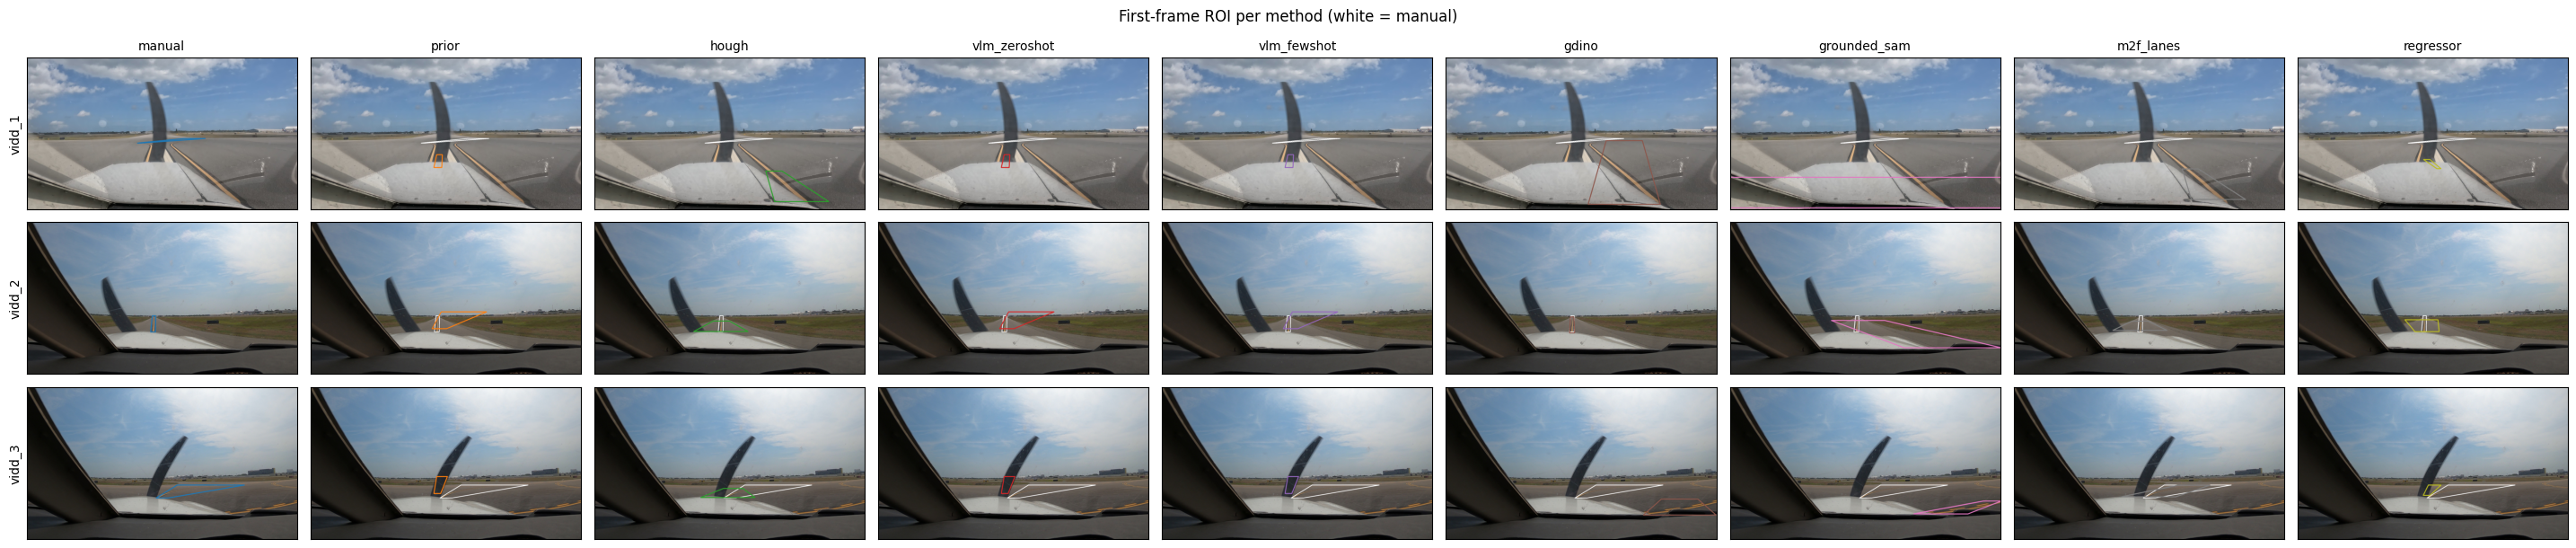

In [24]:
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
COLORS = {m: tuple(int(c) for c in np.array(plt.cm.tab10(i)[:3][::-1]) * 255) for i, m in enumerate(methods_A)}

# 8.1 ROI gallery: one row per video, one column per method (manual ROI in white, when available)
fig, axes = plt.subplots(len(VIDEOS), len(methods_A), figsize=(3.2 * len(methods_A), 2.1 * len(VIDEOS)), squeeze=False)
for r, v in enumerate(VIDEOS):
    p0 = FRAMES[v][0]
    for c, m in enumerate(methods_A):
        vis = load(p0)
        manual0 = MANUAL.get(f"{v}/{p0.name}")
        if manual0 is not None and m != "manual":
            vis = draw_quad(vis, manual0, (255, 255, 255), 3)
        vis = draw_quad(vis, first_quads[(m, v)], COLORS[m], 6)
        axes[r, c].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(m, fontsize=10)
        if c == 0:
            axes[r, c].set_ylabel(v)
fig.suptitle("First-frame ROI per method (white = manual)")
fig.tight_layout()
fig.savefig(FIG / "roi_gallery.png", dpi=150)
plt.show()

In [ ]:
# FOR THE REPORT. Ignore this


FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

COLORS = {
    m: tuple(int(c) for c in np.array(plt.cm.tab10(i)[:3][::-1]) * 255)
    for i, m in enumerate(methods_A)
}

# 8.1 ROI gallery: one figure per method, one row per video
for m in methods_A:
    fig, axes = plt.subplots(
        len(VIDEOS), 1,
        figsize=(4.8, 2.7 * len(VIDEOS)),
        squeeze=False
    )

    for r, v in enumerate(VIDEOS):
        p0 = FRAMES[v][0]
        vis = load(p0)

        manual0 = MANUAL.get(f"{v}/{p0.name}")
        if manual0 is not None and m != "manual":
            vis = draw_quad(vis, manual0, (255, 255, 255), 3)

        vis = draw_quad(vis, first_quads[(m, v)], COLORS[m], 6)

        ax = axes[r, 0]
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylabel(v, fontsize=10)

    fig.suptitle(f"First-frame ROI: {m} (white = manual)", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG / f"roi_gallery_{m}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)


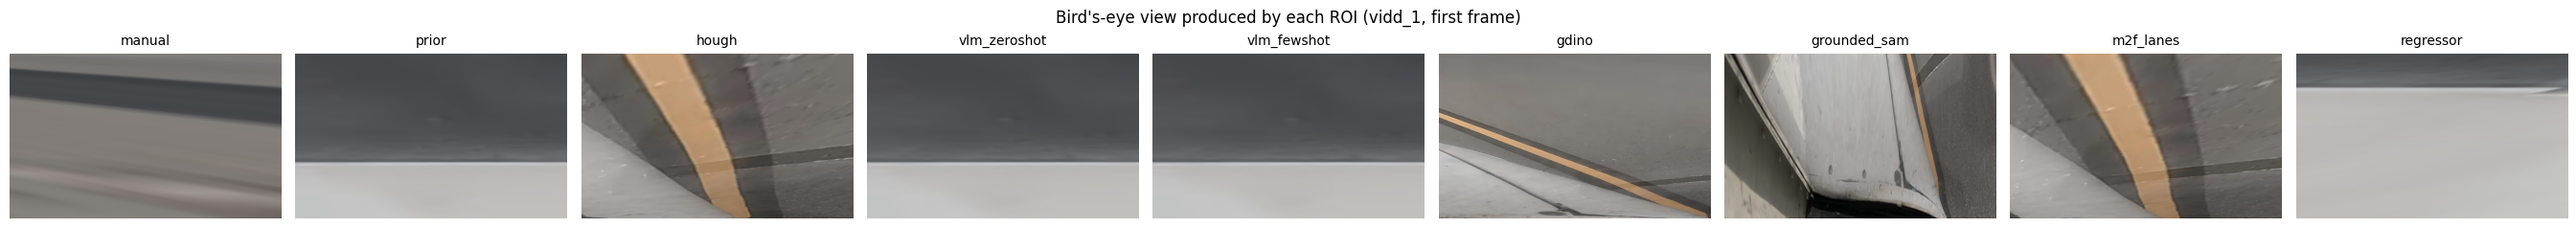

In [20]:
# 8.2 bird's-eye views: what each ROI hands to ALINA's color threshold + histogram
v = "vidd_1"
fig, axes = plt.subplots(1, len(methods_A), figsize=(3 * len(methods_A), 2.4), squeeze=False)
for c, m in enumerate(methods_A):
    axes[0, c].imshow(cv2.cvtColor(birds_eye(load(FRAMES[v][0]), first_quads[(m, v)]), cv2.COLOR_BGR2RGB))
    axes[0, c].set_title(m, fontsize=10); axes[0, c].axis("off")
fig.suptitle(f"Bird's-eye view produced by each ROI ({v}, first frame)")
fig.tight_layout()
fig.savefig(FIG / "birds_eye.png", dpi=150)
plt.show()

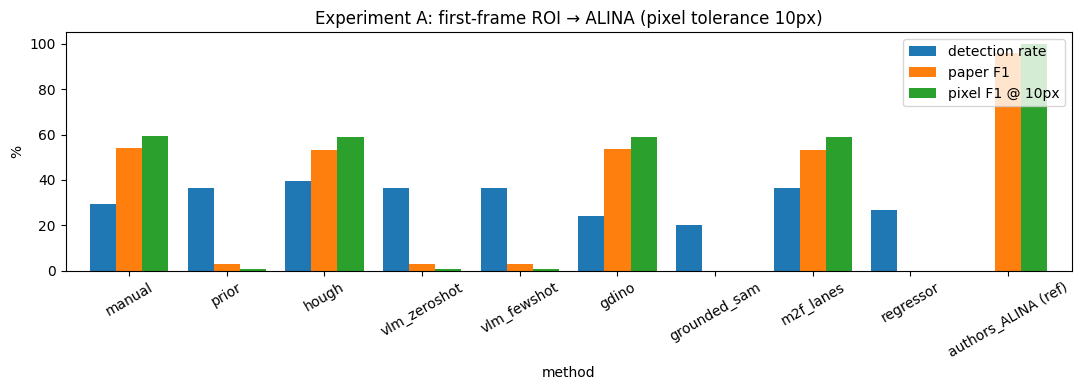

In [21]:
# 8.3 Exp A metrics
plot_df = summary_A[["detection_rate", "paper_F1", "pix_F1"]]
ax = plot_df.plot.bar(figsize=(11, 4), rot=30, width=0.8)
ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.set_title(f"Experiment A: first-frame ROI → ALINA (pixel tolerance {PIXEL_TOL}px)")
ax.legend(["detection rate", "paper F1", f"pixel F1 @ {PIXEL_TOL}px"], loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "expA_metrics.png", dpi=150); plt.show()

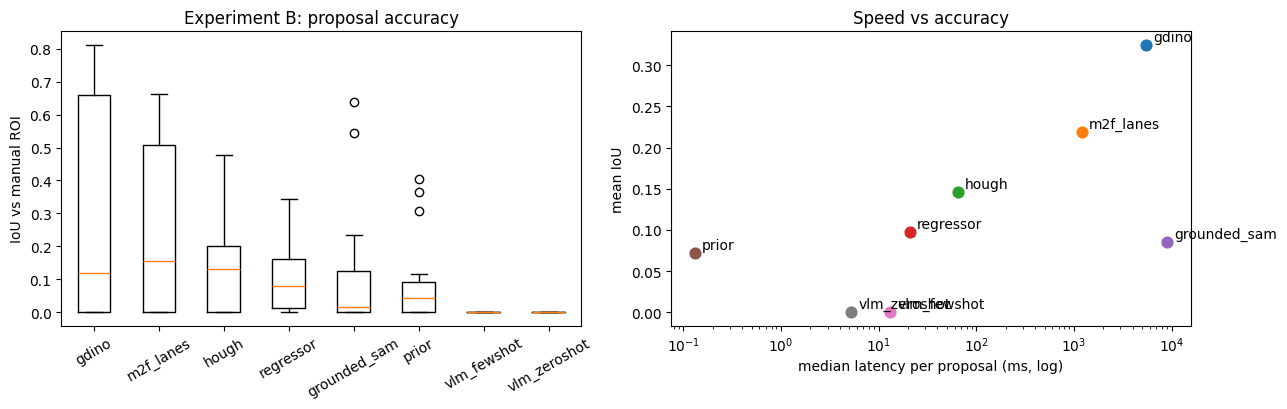

In [22]:
# 8.4 Exp B: IoU distributions and speed/accuracy trade-off
if HAS_LABELS:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
    order = summary_B.sort_values("iou_mean", ascending=False).index.tolist()
    a1.boxplot([frames_B.loc[frames_B.method == m, "iou"] for m in order], tick_labels=order)
    a1.set_ylabel("IoU vs manual ROI"); a1.set_title("Experiment B: proposal accuracy"); a1.tick_params(axis="x", rotation=30)
    for m in order:
        a2.scatter(summary_B.loc[m, "latency_ms_median"], summary_B.loc[m, "iou_mean"], s=60)
        a2.annotate(m, (summary_B.loc[m, "latency_ms_median"], summary_B.loc[m, "iou_mean"]), xytext=(5, 3), textcoords="offset points")
    a2.set_xscale("log"); a2.set_xlabel("median latency per proposal (ms, log)"); a2.set_ylabel("mean IoU"); a2.set_title("Speed vs accuracy")
    plt.tight_layout(); plt.savefig(FIG / "expB_iou.png", dpi=150); plt.show()

## 9. Best method

The ranking uses **mean paper F1** from Exp A, since that's the assignment's metric. Pixel F1 breaks ties, then detection rate. The manual and reference rows are excluded. The choice is written to `outputs/task3a/best_method.json` so Task 3b and the end-to-end demo can load it.

Exp A rests on only 17 GT frames from two videos. Before relying on the ranking, check that it agrees with the Exp B IoU ranking, and say so in the report if it doesn't.

In [23]:
candidates = summary_A.drop(index=[m for m in summary_A.index if m == "manual" or "ref" in m])
ranked = candidates.sort_values(["paper_F1", "pix_F1", "detection_rate"], ascending=False)
best = ranked.index[0]
print("Ranking (Exp A):", list(ranked.index))
if HAS_LABELS:
    print("Ranking (Exp B, IoU):", list(summary_B.sort_values("iou_mean", ascending=False).index))
print("Best method:", best)

(OUT / "best_method.json").write_text(json.dumps({
    "method": best,
    "seed": SEED,
    "first_frame_rois": {v: first_quads[(best, v)].round(1).tolist() for v in VIDEOS},
    "summary": summary_A.loc[best].drop("family").round(3).to_dict(),
}, indent=1))

Ranking (Exp A): ['gdino', 'hough', 'm2f_lanes', 'prior', 'vlm_zeroshot', 'vlm_fewshot', 'regressor', 'grounded_sam']
Ranking (Exp B, IoU): ['gdino', 'm2f_lanes', 'hough', 'regressor', 'grounded_sam', 'prior', 'vlm_fewshot', 'vlm_zeroshot']
Best method: gdino


TypeError: Expected numeric dtype, got object instead.